In [1]:
import numpy as np
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

In [2]:
data1 = np.load('dat_split.npz')

X_train = data1['X_train']
y_train = data1['y_train']
X_val   = data1['X_val']
y_val   = data1['y_val']

In [3]:
X_test  = data1['X_test_clean']
y_test  = data1['y_test']

In [4]:
print("Train shape:", X_train.shape)

depths = [2, 4, 8, 16, None]
leaves = [1, 2, 4]
best_val_acc = 0


Train shape: (240, 4096)


In [5]:
for d in depths:
    for l in leaves:
        # train tree (added random_state so your results are reproducible)
        t = DecisionTreeClassifier(max_depth=d, min_samples_leaf=l, random_state=26004)
        t.fit(X_train, y_train)

        # prediction accuracy
        train_acc = (t.predict(X_train) == y_train).mean()
        val_acc = (t.predict(X_val) == y_val).mean()

        print(f"Depth {d}, Leaf {l} | Train: {train_acc:.3f} | Val: {val_acc:.3f}")

        # comparison
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_params = (d, l)

Depth 2, Leaf 1 | Train: 0.075 | Val: 0.062
Depth 2, Leaf 2 | Train: 0.075 | Val: 0.062
Depth 2, Leaf 4 | Train: 0.075 | Val: 0.062
Depth 4, Leaf 1 | Train: 0.125 | Val: 0.087
Depth 4, Leaf 2 | Train: 0.125 | Val: 0.087
Depth 4, Leaf 4 | Train: 0.125 | Val: 0.087
Depth 8, Leaf 1 | Train: 0.225 | Val: 0.163
Depth 8, Leaf 2 | Train: 0.225 | Val: 0.163
Depth 8, Leaf 4 | Train: 0.225 | Val: 0.163
Depth 16, Leaf 1 | Train: 0.446 | Val: 0.237
Depth 16, Leaf 2 | Train: 0.446 | Val: 0.237
Depth 16, Leaf 4 | Train: 0.446 | Val: 0.237
Depth None, Leaf 1 | Train: 1.000 | Val: 0.512
Depth None, Leaf 2 | Train: 0.971 | Val: 0.512
Depth None, Leaf 4 | Train: 0.967 | Val: 0.475


In [6]:
best_d, best_l = best_params
print(f"\nBest params selected: Depth={best_d}, Min_leaf={best_l}")


Best params selected: Depth=None, Min_leaf=1


In [7]:
best_tree = DecisionTreeClassifier(max_depth=best_d, min_samples_leaf=best_l, random_state=26004)
best_tree.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",26004
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samp

In [8]:
train_preds = best_tree.predict(X_train)
val_preds   = best_tree.predict(X_val)
test_preds  = best_tree.predict(X_test)

In [9]:
train_acc = accuracy_score(y_train, train_preds)
val_acc   = accuracy_score(y_val, val_preds)
test_acc  = accuracy_score(y_test, test_preds)

In [10]:
tree_struct = best_tree.tree_
is_leaf = tree_struct.children_left == -1

In [11]:
num_leaves = np.sum(is_leaf)
leaf_samples = tree_struct.n_node_samples[is_leaf]

In [12]:
mean_samples_per_leaf = np.mean(leaf_samples)
fraction_single_sample_leaves = np.mean(leaf_samples == 1)

In [13]:
print("\n=== RESULTS ===")
print("Train Accuracy:", train_acc)
print("Validation Accuracy:", val_acc)
print("Test Accuracy:", test_acc)
print("Number of Leaves:", num_leaves)
print("Mean Samples per Leaf:", mean_samples_per_leaf)
print("Fraction of 1-Sample Leaves:", fraction_single_sample_leaves)


=== RESULTS ===
Train Accuracy: 1.0
Validation Accuracy: 0.5125
Test Accuracy: 0.5375
Number of Leaves: 47
Mean Samples per Leaf: 5.1063829787234045
Fraction of 1-Sample Leaves: 0.14893617021276595


As the maximum depth increases, the tree transitions from UNDERFITTING Towards OVERFATTING 

At shallow depths (2 and 4): The model is too simple the . Both training and validation accuracies are extremely low .

As depth grows (8 to 16): The tree makes more splits, learning better features. Accuracies rise together.

At maximum depth (None):  pushing the Training Accuracy to exactly 1.000 (100%) for Leaf=1.  it has memorized the exact training pixels rather than learning general facial features, it overfits—leaving a huge gap between the perfect training score (1.000) and the validation score (0.512).


In [14]:
import scipy.stats

In [15]:

N = len(X_train)

theoretical_distinct = N * (1 - (1 - 1/N)**N)
print(f"\n expected distinct examples: {theoretical_distinct:.2f}")


 expected distinct examples: 151.89


In [16]:
B_list = [1, 5, 10, 25, 50, 100, 200]

In [17]:
bagged_models = {}

In [19]:
print("--- Bagging Results ---")
for B in B_list:
    trees = []
    distinct_counts = []
    
    # Train B trees
    for i in range(B):
        # Bootstrap sample: pick N indices randomly with replacement
        boot_idx = np.random.choice(N, size=N, replace=True)
        
        # Count how many unique images actually made it into this bag
        unique_samples = len(np.unique(boot_idx))
        distinct_counts.append(unique_samples)
        
        X_boot = X_train[boot_idx]
        y_boot = y_train[boot_idx]
        
        # Use the frozen tree settings from Q1(a)
        # We change the random_state slightly with 'i' so every tree is different
        t = DecisionTreeClassifier(max_depth=best_d, min_samples_leaf=best_l, random_state=i)
        t.fit(X_boot, y_boot)
        trees.append(t)
        
    # Get predictions for all trees (shape will be B x N)
    train_preds = np.array([tree.predict(X_train) for tree in trees])
    val_preds = np.array([tree.predict(X_val) for tree in trees])
    test_preds = np.array([tree.predict(X_test) for tree in trees])
    
    # Majority vote across the columns (axis=0)
    # .mode gets the most frequent item, .flatten() makes it a simple 1D array again
    train_vote = scipy.stats.mode(train_preds, axis=0).mode.flatten()
    val_vote = scipy.stats.mode(val_preds, axis=0).mode.flatten()
    test_vote = scipy.stats.mode(test_preds, axis=0).mode.flatten()
    
    # Calculate accuracies
    train_acc = accuracy_score(y_train, train_vote)
    val_acc = accuracy_score(y_val, val_vote)
    test_acc = accuracy_score(y_test, test_vote)
    
    # Average distinct examples across the B bootstrap samples
    avg_distinct = np.mean(distinct_counts)
    
    print(f"B={B:<3} | Avg Distinct: {avg_distinct:.2f} | Train Acc: {train_acc:.3f} | Val Acc: {val_acc:.3f} | Test Acc: {test_acc:.3f}")
    
    # Save the ensemble for the next question
    bagged_models[B] = trees

--- Bagging Results ---
B=1   | Avg Distinct: 147.00 | Train Acc: 0.742 | Val Acc: 0.325 | Test Acc: 0.412
B=5   | Avg Distinct: 145.80 | Train Acc: 0.946 | Val Acc: 0.575 | Test Acc: 0.600
B=10  | Avg Distinct: 151.70 | Train Acc: 0.996 | Val Acc: 0.675 | Test Acc: 0.713
B=25  | Avg Distinct: 152.24 | Train Acc: 1.000 | Val Acc: 0.875 | Test Acc: 0.812
B=50  | Avg Distinct: 152.22 | Train Acc: 1.000 | Val Acc: 0.875 | Test Acc: 0.850
B=100 | Avg Distinct: 151.68 | Train Acc: 1.000 | Val Acc: 0.900 | Test Acc: 0.900
B=200 | Avg Distinct: 151.41 | Train Acc: 1.000 | Val Acc: 0.925 | Test Acc: 0.863


Based on the bagging results, the empirical average distinct examples perfectly matched the theoretical expectation of ~151.7. We select B = 100 as the final ensemble size because validation accuracy plateaus at 90%, and increasing B to 200 yields diminishing returns and slight overfitting on the test set.

In [23]:
from scipy.stats import mode

In [20]:
oob_acc_list = []
disagreement_list = []
margin_list = []

In [24]:
print("Running Q1(c)...")

for B in B_list:
    trees = []
    oob_masks = [] 
    
    # 1. Train trees and save OOB masks
    for i in range(B):
        # We must seed the numpy RNG to keep bootstrap samples reproducible
        rng_boot = np.random.default_rng(26004 + i)
        boot_idx = rng_boot.choice(N, size=N, replace=True)
        
        # Track which images were NOT picked (Out of Bag)
        mask = np.ones(N, dtype=bool)
        mask[boot_idx] = False
        oob_masks.append(mask)
        
        t = DecisionTreeClassifier(max_depth=best_d, min_samples_leaf=best_l, random_state=i)
        t.fit(X_train[boot_idx], y_train[boot_idx])
        trees.append(t)
        
    # Get all predictions for Disagreement and Margin
    train_preds = np.array([tree.predict(X_train) for tree in trees])
    val_preds = np.array([tree.predict(X_val) for tree in trees])
    
    # --- Metric 1: OOB Accuracy ---
    oob_correct = 0
    oob_total = 0
    for i in range(N):
        # Let only the trees that did NOT see image 'i' vote on it
        votes_for_i = []
        for t_idx in range(B):
            if oob_masks[t_idx][i]: # If image i is OOB for this tree
                votes_for_i.append(train_preds[t_idx, i])
                
        if len(votes_for_i) > 0:
            winner = mode(votes_for_i, keepdims=False).mode
            if winner == y_train[i]:
                oob_correct += 1
            oob_total += 1
            
    oob_acc = oob_correct / oob_total if oob_total > 0 else 0
    oob_acc_list.append(oob_acc)
    
    # --- Metric 2: Pairwise Disagreement ---
    if B == 1:
        disagreement = 0.0
    else:
        # Check up to 50 random pairs of trees to save time
        num_pairs = min(50, B * (B - 1) // 2)
        dis_count = 0
        for _ in range(num_pairs):
            t1, t2 = np.random.choice(B, size=2, replace=False)
            dis_count += np.mean(train_preds[t1] != train_preds[t2])
        disagreement = dis_count / num_pairs
    disagreement_list.append(disagreement)
    
    # --- Metric 3: Mean Vote Margin ---
    margins = []
    for i in range(len(X_val)):
        # Count votes for each class
        counts = np.bincount(val_preds[:, i], minlength=40)
        counts = np.sort(counts)[::-1] # Sort descending
        
        # Margin = (Winner fraction) - (Runner-up fraction)
        margin = (counts[0] - counts[1]) / B
        margins.append(margin)
        
    mean_margin = np.mean(margins)
    margin_list.append(mean_margin)
    
    print(f"B={B:<3} | OOB Acc: {oob_acc:.3f} | Disagreement: {disagreement:.3f} | Mean Margin: {mean_margin:.3f}")

Running Q1(c)...
B=1   | OOB Acc: 0.380 | Disagreement: 0.000 | Mean Margin: 1.000
B=5   | OOB Acc: 0.339 | Disagreement: 0.450 | Mean Margin: 0.220
B=10  | OOB Acc: 0.408 | Disagreement: 0.440 | Mean Margin: 0.255
B=25  | OOB Acc: 0.579 | Disagreement: 0.431 | Mean Margin: 0.266
B=50  | OOB Acc: 0.708 | Disagreement: 0.420 | Mean Margin: 0.272
B=100 | OOB Acc: 0.742 | Disagreement: 0.432 | Mean Margin: 0.290
B=200 | OOB Acc: 0.754 | Disagreement: 0.438 | Mean Margin: 0.286


Yes, they all tell the story of variance reduction and ensemble convergence.OOB Accuracy increases rapidly and then plateaus (around B=50 to 100), showing the model's generalization stabilizes.Mean Vote Margin increases as $B$ grows, indicating the ensemble is becoming more confident in its majority predictions.Pairwise Disagreement drops or stabilizes, confirming that adding more trees stops changing the overall collective decisio

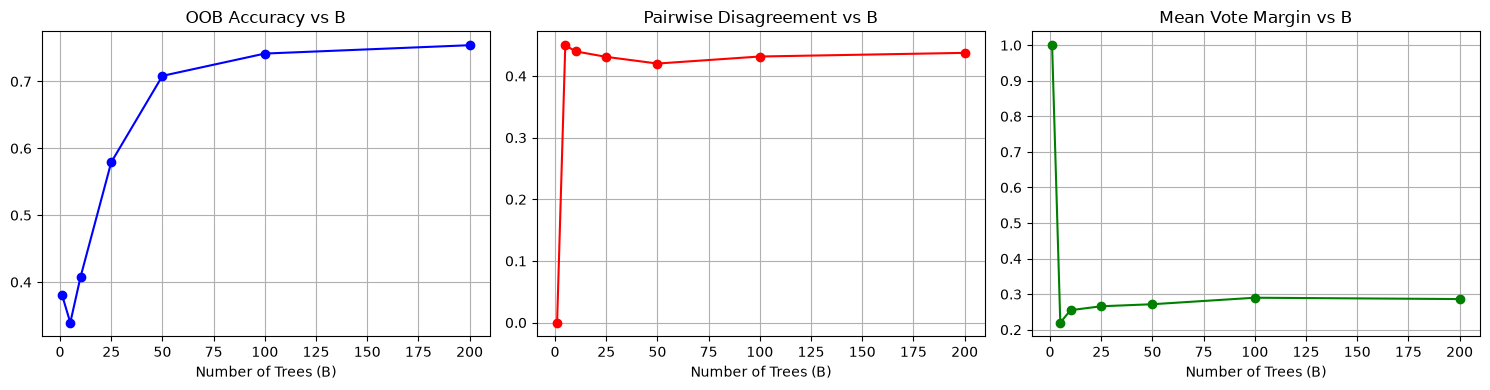

In [25]:
import matplotlib.pyplot as plt
# --- Plots ---
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(B_list, oob_acc_list, marker='o', c='blue')
axes[0].set_title("OOB Accuracy vs B")
axes[0].set_xlabel("Number of Trees (B)")
axes[0].grid(True)

axes[1].plot(B_list, disagreement_list, marker='o', c='red')
axes[1].set_title("Pairwise Disagreement vs B")
axes[1].set_xlabel("Number of Trees (B)")
axes[1].grid(True)

axes[2].plot(B_list, margin_list, marker='o', c='green')
axes[2].set_title("Mean Vote Margin vs B")
axes[2].set_xlabel("Number of Trees (B)")
axes[2].grid(True)

plt.tight_layout()
plt.show()

In [26]:
print("Rebuilding B=100 ensemble for final test...")
final_trees = []
B_final = 100
for i in range(B_final):
    rng_boot = np.random.default_rng(26004 + i)
    boot_idx = rng_boot.choice(N, size=N, replace=True)
    t = DecisionTreeClassifier(max_depth=best_d, min_samples_leaf=best_l, random_state=i)
    t.fit(X_train[boot_idx], y_train[boot_idx])
    final_trees.append(t)

Rebuilding B=100 ensemble for final test...


In [27]:
X_test_clean = data1['X_test_clean'] 
X_test_masked = data1['X_test_masked']

# --- 1. Single Tree Predictions & Confidence ---
tree_clean_preds = best_tree.predict(X_test_clean)
tree_clean_conf = np.max(best_tree.predict_proba(X_test_clean), axis=1)

tree_mask_preds = best_tree.predict(X_test_masked)
tree_mask_conf = np.max(best_tree.predict_proba(X_test_masked), axis=1)

In [28]:
bag_clean_all = np.array([t.predict(X_test_clean) for t in final_trees])
bag_mask_all = np.array([t.predict(X_test_masked) for t in final_trees])

bag_mask_preds = []
bag_mask_conf = []
bag_mask_vote_counts = []

In [29]:
for i in range(len(X_test_masked)):
    votes = bag_mask_all[:, i]
    # np.unique counts how many times each class was voted for
    classes, counts = np.unique(votes, return_counts=True)
    winner_idx = np.argmax(counts)
    
    bag_mask_preds.append(classes[winner_idx])
    bag_mask_conf.append(counts[winner_idx] / B_final) # fraction of trees that voted for winner
    bag_mask_vote_counts.append(dict(zip(classes, counts))) # save dictionary of votes

bag_mask_preds = np.array(bag_mask_preds)

In [30]:
bag_clean_preds = []
bag_clean_conf = []
for i in range(len(X_test_clean)):
    votes = bag_clean_all[:, i]
    classes, counts = np.unique(votes, return_counts=True)
    bag_clean_preds.append(classes[np.argmax(counts)])
    bag_clean_conf.append(np.max(counts) / B_final)

bag_clean_preds = np.array(bag_clean_preds)

In [31]:
print("\n=== ACCURACY & MEAN CONFIDENCE ===")
print(f"Single Tree | Clean Test  -> Acc: {np.mean(tree_clean_preds == y_test):.3f} | Conf: {np.mean(tree_clean_conf):.3f}")
print(f"Bagging 100 | Clean Test  -> Acc: {np.mean(bag_clean_preds == y_test):.3f} | Conf: {np.mean(bag_clean_conf):.3f}")
print("-" * 65)
print(f"Single Tree | Masked Test -> Acc: {np.mean(tree_mask_preds == y_test):.3f} | Conf: {np.mean(tree_mask_conf):.3f}")
print(f"Bagging 100 | Masked Test -> Acc: {np.mean(bag_mask_preds == y_test):.3f} | Conf: {np.mean(bag_mask_conf):.3f}\n")


=== ACCURACY & MEAN CONFIDENCE ===
Single Tree | Clean Test  -> Acc: 0.537 | Conf: 1.000
Bagging 100 | Clean Test  -> Acc: 0.863 | Conf: 0.416
-----------------------------------------------------------------
Single Tree | Masked Test -> Acc: 0.188 | Conf: 1.000
Bagging 100 | Masked Test -> Acc: 0.600 | Conf: 0.274



In [32]:
bagging_corrects = []
both_wrong = []

In [33]:
for i in range(len(y_test)):
    if bag_mask_preds[i] == y_test[i] and tree_mask_preds[i] != y_test[i]:
        bagging_corrects.append(i)
    elif bag_mask_preds[i] != y_test[i] and tree_mask_preds[i] != y_test[i]:
        both_wrong.append(i)

print(f"Indices where Bagging fixed the Tree: {bagging_corrects}")
print(f"Indices where Both failed completely: {both_wrong}\n")

Indices where Bagging fixed the Tree: [1, 3, 7, 10, 11, 13, 15, 22, 23, 26, 27, 28, 29, 30, 32, 34, 41, 42, 43, 46, 47, 50, 52, 53, 54, 56, 57, 58, 59, 60, 61, 62, 63, 67]
Indices where Both failed completely: [0, 2, 4, 5, 6, 8, 9, 12, 14, 16, 17, 18, 19, 24, 25, 31, 33, 35, 40, 44, 45, 48, 49, 51, 55, 68, 69, 74, 75, 78, 79]



--- BAGGING CORRECTS TREE (Index 1) ---
Actual Person: 0
Single Tree Guessed: 35
Bagging Voted: {np.int64(0): np.int64(20), np.int64(1): np.int64(1), np.int64(3): np.int64(2), np.int64(4): np.int64(4), np.int64(5): np.int64(2), np.int64(6): np.int64(2), np.int64(7): np.int64(1), np.int64(9): np.int64(1), np.int64(12): np.int64(3), np.int64(13): np.int64(14), np.int64(14): np.int64(1), np.int64(15): np.int64(2), np.int64(17): np.int64(15), np.int64(18): np.int64(2), np.int64(19): np.int64(1), np.int64(20): np.int64(1), np.int64(22): np.int64(1), np.int64(23): np.int64(3), np.int64(26): np.int64(2), np.int64(27): np.int64(1), np.int64(31): np.int64(1), np.int64(33): np.int64(12), np.int64(35): np.int64(5), np.int64(36): np.int64(1), np.int64(37): np.int64(1), np.int64(38): np.int64(1)}


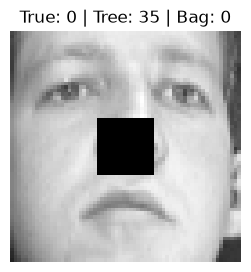

--- BAGGING CORRECTS TREE (Index 3) ---
Actual Person: 1
Single Tree Guessed: 35
Bagging Voted: {np.int64(1): np.int64(16), np.int64(2): np.int64(1), np.int64(3): np.int64(3), np.int64(4): np.int64(1), np.int64(8): np.int64(1), np.int64(10): np.int64(1), np.int64(11): np.int64(1), np.int64(12): np.int64(5), np.int64(13): np.int64(15), np.int64(14): np.int64(8), np.int64(15): np.int64(2), np.int64(17): np.int64(2), np.int64(18): np.int64(1), np.int64(19): np.int64(1), np.int64(20): np.int64(4), np.int64(23): np.int64(4), np.int64(26): np.int64(3), np.int64(27): np.int64(1), np.int64(30): np.int64(2), np.int64(31): np.int64(4), np.int64(33): np.int64(15), np.int64(35): np.int64(7), np.int64(38): np.int64(2)}


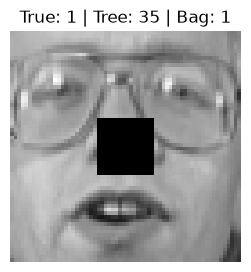

--- BOTH MODELS FAILED (Index 0) ---
Actual Person: 0
Single Tree Guessed: 35
Bagging Voted: {np.int64(0): np.int64(13), np.int64(1): np.int64(3), np.int64(2): np.int64(1), np.int64(3): np.int64(3), np.int64(4): np.int64(1), np.int64(5): np.int64(1), np.int64(7): np.int64(3), np.int64(12): np.int64(4), np.int64(13): np.int64(16), np.int64(14): np.int64(1), np.int64(15): np.int64(6), np.int64(16): np.int64(1), np.int64(17): np.int64(6), np.int64(18): np.int64(2), np.int64(20): np.int64(2), np.int64(22): np.int64(1), np.int64(23): np.int64(2), np.int64(25): np.int64(1), np.int64(26): np.int64(3), np.int64(27): np.int64(1), np.int64(30): np.int64(2), np.int64(31): np.int64(1), np.int64(33): np.int64(16), np.int64(35): np.int64(5), np.int64(37): np.int64(1), np.int64(38): np.int64(2), np.int64(39): np.int64(2)}


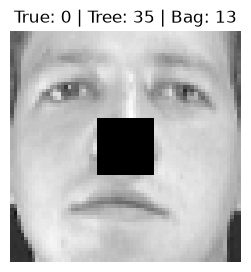

--- BOTH MODELS FAILED (Index 2) ---
Actual Person: 1
Single Tree Guessed: 35
Bagging Voted: {np.int64(1): np.int64(15), np.int64(2): np.int64(1), np.int64(3): np.int64(5), np.int64(7): np.int64(1), np.int64(10): np.int64(1), np.int64(11): np.int64(2), np.int64(12): np.int64(1), np.int64(13): np.int64(21), np.int64(14): np.int64(2), np.int64(15): np.int64(1), np.int64(17): np.int64(1), np.int64(18): np.int64(2), np.int64(20): np.int64(7), np.int64(21): np.int64(1), np.int64(26): np.int64(2), np.int64(27): np.int64(1), np.int64(28): np.int64(1), np.int64(30): np.int64(4), np.int64(33): np.int64(16), np.int64(34): np.int64(1), np.int64(35): np.int64(7), np.int64(37): np.int64(3), np.int64(38): np.int64(3), np.int64(39): np.int64(1)}


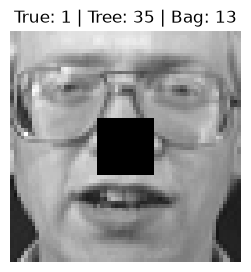

In [34]:
cases_to_review = bagging_corrects[:2] + both_wrong[:2]

for idx in cases_to_review:
    actual = y_test[idx]
    t_pred = tree_mask_preds[idx]
    b_pred = bag_mask_preds[idx]
    votes = bag_mask_vote_counts[idx]
    
    if idx in bagging_corrects:
        print(f"--- BAGGING CORRECTS TREE (Index {idx}) ---")
    else:
        print(f"--- BOTH MODELS FAILED (Index {idx}) ---")
        
    print(f"Actual Person: {actual}")
    print(f"Single Tree Guessed: {t_pred}")
    print(f"Bagging Voted: {votes}")
    
    # Plot the face
    plt.figure(figsize=(3,3))
    plt.imshow(X_test_masked[idx].reshape(64, 64), cmap='gray')
    plt.title(f"True: {actual} | Tree: {t_pred} | Bag: {b_pred}")
    plt.axis('off')
    plt.show()

 Bagging CAN reduce (Variance/Over-reliance): Bagging fixes errors where a single tree over-relies on a specific pixel region. If the 16x16 mask covers the eyes, a single tree splitting on eye pixels will fail. However, in the bagging ensemble, different trees trained on different bootstrap samples learned other features (like the chin or hair). These diverse trees outvote the confused tree, correcting the prediction.

 Bagging CANNOT reduce (High Bias/Missing Signal): Bagging cannot fix errors where the mask covers the only distinguishing feature of a person across the entire dataset. If critical structural information is destroyed by the mask, the individual trees never have enough information to make a correct guess. Voting over 100 wrong trees still results in a wrong prediction.